## Homework 5

**Your name**. 

In [2]:
using LinearAlgebra, Plots
using LaTeXStrings

## Q 7.2.5

Let $A$ be a 2x2 matrix defined below.

(a) Find the eigenvalue decomposition of $A$ using `eigen`. The result is a data structure with two components, `.values` and `.vectors`

(b) Write a function `p_matrix` that uses Eq. (7.2.7) to evaluate $p(A)$, where $p(x) = (x - \pi)^4$. You can find a matrix inverse using the function `inv` and you can construct a matrix from its diagonal entries using `diagm`.

(c) Write a function `cos_matrix` that uses the function analog of (7.2.7) to evaluate $p(A) = \cos(A)$.

In [3]:
A = [ 4 1; 4 4] * pi / 6

2×2 Matrix{Float64}:
 2.0944  0.523599
 2.0944  2.0944

Compare the numerical value of your solution to the "long way", computing the fourth power of $A - \pi$ explicitly. Also compare to Julia's built-in algorithm for computing cosine of a matrix.

In [4]:
(A - one(A) * pi) ^ 4 # built-in calculation -- the notation hides the algorithm

2×2 Matrix{Float64}:
   9.62065  -4.81033
 -19.2413    9.62065

In [5]:
cos(A) # built-in

2×2 Matrix{Float64}:
 -0.25  -0.375
 -1.5   -0.25

In [6]:
ev = eigen(A)

Eigen{Float64, Float64, Matrix{Float64}, Vector{Float64}}
values:
2-element Vector{Float64}:
 1.0471975511965976
 3.141592653589793
vectors:
2×2 Matrix{Float64}:
 -0.447214  0.447214
  0.894427  0.894427

_Solution_

(a) The eigenvalue decomposition is 

$$
    A = P\Lambda P^{-1},\quad 
    \Lambda = \begin{bmatrix}
        \lambda_1&0\\0&\lambda_2
    \end{bmatrix} = \begin{bmatrix}
        1.0472&0\\0&3.1416
    \end{bmatrix},\quad P = \begin{bmatrix}
        \mathbf{v_1}&\mathbf{v_2}
    \end{bmatrix} = \begin{bmatrix}
        -0.4472&0.4472\\0.8944&0.8944
    \end{bmatrix}
$$

and $p^{-1}=\begin{bmatrix}
        -1.1180&0.5590\\1.1180&0.5590
    \end{bmatrix}$, thus

$$
    A = \begin{bmatrix}
        -0.4472&0.4472\\0.8944&0.8944
    \end{bmatrix}\begin{bmatrix}
        1.0472&0\\0&3.1416
    \end{bmatrix}\begin{bmatrix}
        -1.1180&0.5590\\1.1180&0.5590
    \end{bmatrix}
$$

In [7]:
# (a)
ev = eigen(A)
display(ev)
display(inv(ev.vectors))
display(ev.vectors * diagm(ev.values) * inv(ev.vectors))

# verify
ev.vectors * diagm(ev.values) * inv(ev.vectors) - A

Eigen{Float64, Float64, Matrix{Float64}, Vector{Float64}}
values:
2-element Vector{Float64}:
 1.0471975511965976
 3.141592653589793
vectors:
2×2 Matrix{Float64}:
 -0.447214  0.447214
  0.894427  0.894427

2×2 Matrix{Float64}:
 -1.11803  0.559017
  1.11803  0.559017

2×2 Matrix{Float64}:
 2.0944  0.523599
 2.0944  2.0944

2×2 Matrix{Float64}:
 0.0  1.11022e-16
 0.0  4.44089e-16

(b) $P^{-1}(A-\pi)^4P=(P^{-1}(A-\pi)P)^4=(\Lambda-\pi)^4$, hence $(A-\pi)^4=P(\Lambda-\pi)^4P^{-1}$.

In [8]:
(ev.vectors) * diagm((ev.values .- pi) .^ 4) * inv(ev.vectors) 

2×2 Matrix{Float64}:
   9.62065  -4.81033
 -19.2413    9.62065

(c) Let $p(x)=\cos x=1-\dfrac{x^2}{2!}+\dfrac{x^4}{4!}-\dfrac{x^6}{6!}+\cdots$, then 

$$
    \begin{align}
        p(A)=\cos A &= I-\dfrac{A^2}{2!}+\dfrac{A^4}{4!}-\dfrac{A^6}{6!}+\cdots\\
        & = V\text{diag}(p(\lambda_1), p(\lambda_2), \cdots, p(\lambda_n))V^{-1}\\
        & = V\text{diag}(\cos(\lambda_1), \cos(\lambda_2), \cdots, \cos(\lambda_n))V^{-1}
    \end{align}
$$

In [9]:
ev.vectors * diagm(cos.(ev.values)) * inv(ev.vectors)

2×2 Matrix{Float64}:
 -0.25  -0.375
 -1.5   -0.25

## Q 7.2.8

Eigenvalues of random matrices and their perturbations can be very interesting.

(a) Let A=randn(60,60). Scatter plot its eigenvalues in the complex plane, using aspect_ratio=1 and red diamonds as markers.

(b) Let $E$ be another random $60\times 60$  matrix, and on top of the previous graph, plot the eigenvalues of $A+0.05E$ as blue dots. Repeat this for 100 different values of $E$.

(c) Let T=triu(A). On a new graph, scatter plot the eigenvalues of $T$ in the complex plane. (They all lie on the real axis.)

(d) Repeat part (b) with $T$ in place of $A$.


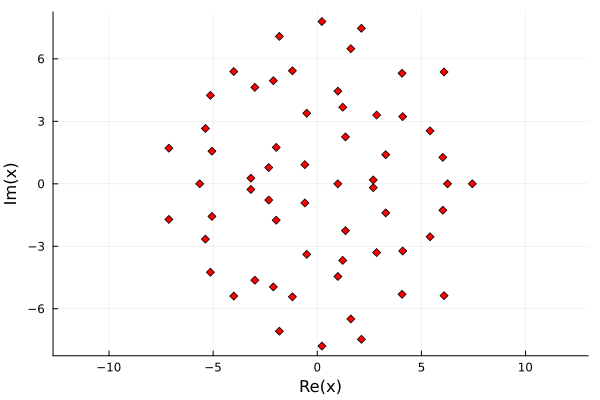

In [10]:
# (a)

A = randn(60, 60);
ev = eigen(A)
scatter(ev.values, shape = :diamond, color = :red, label = "", aspect_ratio = 1)

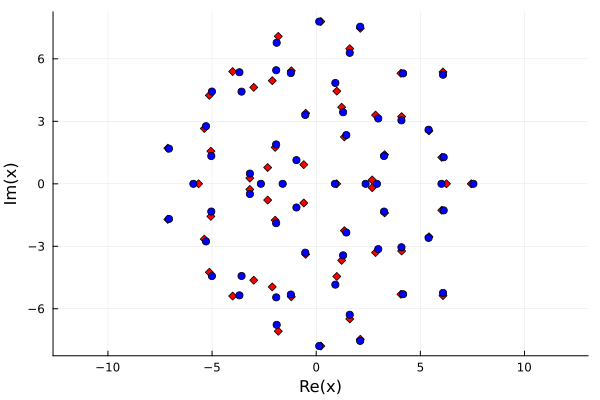

In [11]:
# (b)

E = randn(60, 60);
ev2 = eigen(A + 0.05 * E)
display(scatter!(ev2.values, shape = :circle, color = :blue, label = ""))

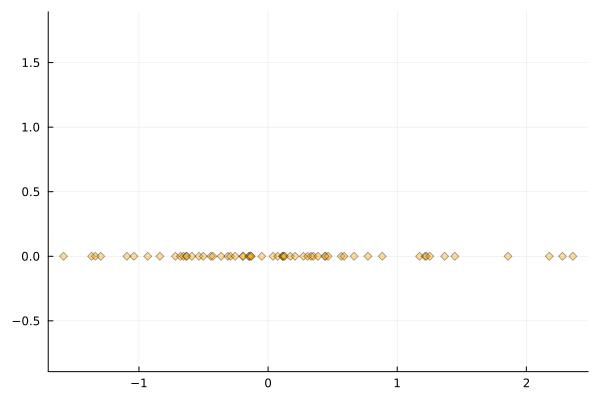

In [12]:
# (c)

T = triu(A)
ev3 = eigen(T)
scatter(real(ev3.values), imag(ev3.values), shape = :diamond, color = :orange, opacity = 0.4, label = "", aspect_ratio = 1)

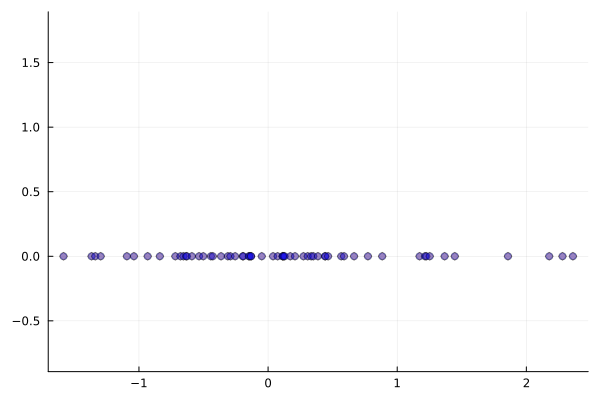

In [13]:
# (d)

ev4 = eigen(T + 0.05 * E)
scatter!(real(ev3.values), imag(ev3.values), shape = :circle, color = :blue, opacity = 0.4, label = "")
current()

## Q 7.3.4

See Demo 7.1.7 for how to get the “mandrill” test image. Make a log-linear scatter plot of the singular values of the matrix of grayscale intensity values. (The shape of this graph is surprisingly similar across a wide range of images.)

In [14]:
using Images, TestImages

_Solution_:

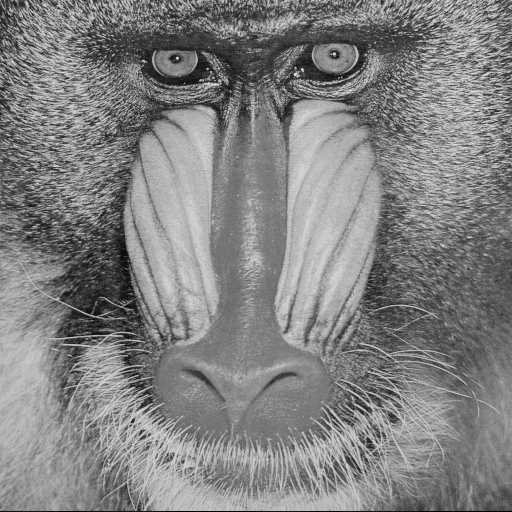

In [15]:
img = Gray.(testimage("mandrill"))

In [16]:
A = Float64.(Gray.(img))

512×512 Matrix{Float64}:
 0.568627   0.219608   0.192157   0.34902   …  0.443137  0.6        0.694118
 0.454902   0.396078   0.156863   0.262745     0.509804  0.584314   0.490196
 0.301961   0.447059   0.180392   0.180392     0.392157  0.345098   0.317647
 0.278431   0.533333   0.372549   0.188235     0.286275  0.294118   0.27451
 0.341176   0.478431   0.517647   0.196078     0.231373  0.313725   0.337255
 0.321569   0.298039   0.623529   0.239216  …  0.333333  0.596078   0.713725
 0.168627   0.2        0.52549    0.509804     0.72549   0.776471   0.643137
 0.129412   0.2        0.435294   0.6          0.631373  0.470588   0.541176
 0.223529   0.188235   0.219608   0.458824     0.529412  0.611765   0.478431
 0.14902    0.12549    0.188235   0.25098      0.254902  0.317647   0.533333
 ⋮                                          ⋱            ⋮          
 0.466667   0.501961   0.564706   0.556863     0.341176  0.321569   0.333333
 0.490196   0.490196   0.52549    0.568627     0.341176  0.3

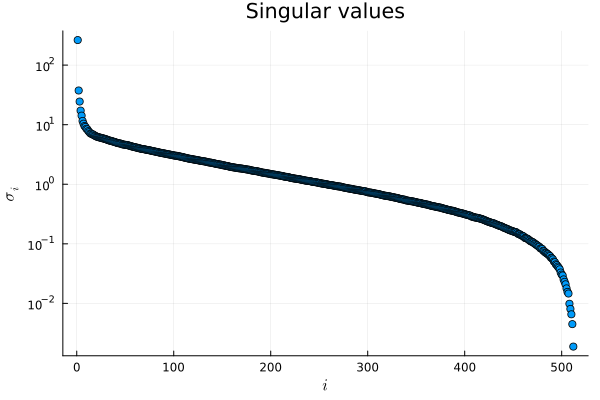

In [17]:
svals = svdvals(A)
scatter(svals,xaxis=(L"i"), yaxis=(:log10,L"\sigma_i"),
title="Singular values", label="")


## Q 7.4.4

The range of the function $R_A(x)$ is a subset of the complex plane known as the field of values of the matrix $A$. Use 500 random (possibly complex - you decide what is needed) vectors to plot points in the field of values of $A$. Then compute its eigenvalues and guess what the exact field of values is.

In [18]:
R(A,x) = x'*A*x / (x' * x)
A = [ 1 0 -2 ; 0 2 0 ; -2 0 1 ]

3×3 Matrix{Int64}:
  1  0  -2
  0  2   0
 -2  0   1

_Solution_:

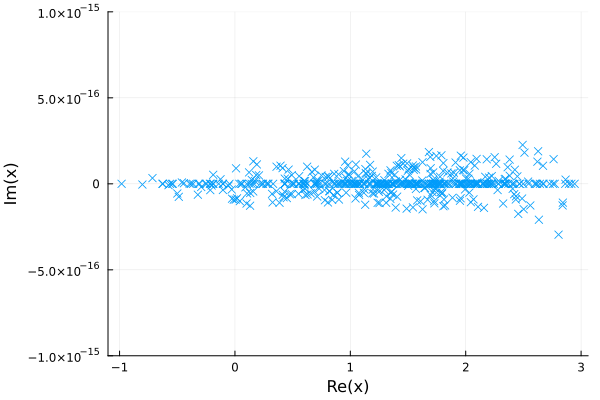

In [19]:
vals = ComplexF64[]
for i = 1:500
    push!(vals, R(A, randn(ComplexF64, 3)))
end

scatter(vals, label = "", mark = :x, ylim=[-1e-15,1e-15])

In [20]:
eigen(A).values

3-element Vector{Float64}:
 -0.9999999999999978
  2.0
  3.0

The exact field of $A$ should probably be $[-1,3]$.

## Q 7.5.5

Following Demo 7.5.2 as a guide, load the “mandrill” test image and convert it to a matrix of floating-point pixel grayscale intensities. Using the SVD, display as images the best approximations of rank 5, 10, 15, and 20.

_Solution_:

In [21]:
A = Float64.(Gray.(testimage("mandrill")))

512×512 Matrix{Float64}:
 0.568627   0.219608   0.192157   0.34902   …  0.443137  0.6        0.694118
 0.454902   0.396078   0.156863   0.262745     0.509804  0.584314   0.490196
 0.301961   0.447059   0.180392   0.180392     0.392157  0.345098   0.317647
 0.278431   0.533333   0.372549   0.188235     0.286275  0.294118   0.27451
 0.341176   0.478431   0.517647   0.196078     0.231373  0.313725   0.337255
 0.321569   0.298039   0.623529   0.239216  …  0.333333  0.596078   0.713725
 0.168627   0.2        0.52549    0.509804     0.72549   0.776471   0.643137
 0.129412   0.2        0.435294   0.6          0.631373  0.470588   0.541176
 0.223529   0.188235   0.219608   0.458824     0.529412  0.611765   0.478431
 0.14902    0.12549    0.188235   0.25098      0.254902  0.317647   0.533333
 ⋮                                          ⋱            ⋮          
 0.466667   0.501961   0.564706   0.556863     0.341176  0.321569   0.333333
 0.490196   0.490196   0.52549    0.568627     0.341176  0.3

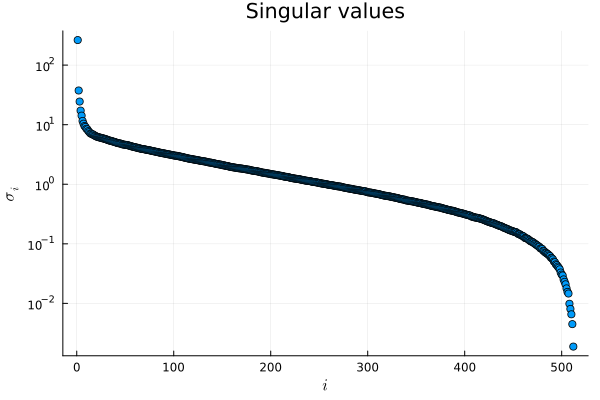

In [22]:
U,σ,V = svd(A)
scatter(σ,xaxis=(L"i"), yaxis=(:log10,L"\sigma_i"),
    title="Singular values", label="")

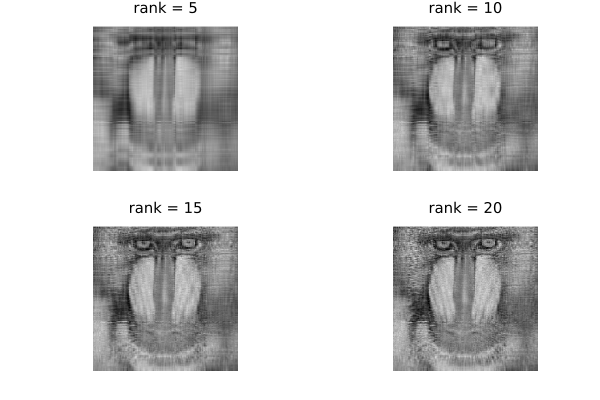

In [23]:
plt = plot(layout=(2,2),frame=:none,aspect_ratio=1,titlefontsize=10)
for i in 1:4
    k = 5i
    Ak = U[:,1:k]*diagm(σ[1:k])*V[:,1:k]'
    plot!(Gray.(Ak),subplot=i,title="rank = $k")
end
plt

## Q 9.5.2

(a) Show that the functions $\sin(r\pi x)$ and $\sin(s\pi x)$ are identical at all of the nodes given in (9.5.2) if 
 for an integer $r-s=mN$. This important fact is called aliasing, and it implies that only finitely many frequencies can be distinguished on a fixed node set.

(b) Demonstrate part (a) with a graph for the case $N=11$, $s=2$, $r=-9$. Specifically, plot the two functions on one graph, and plot points to show that they intersect at all of the interpolation nodes.
            

In [24]:
n = 5
N = 2*n + 1
tk = 2/N .* (-n:1:n);

_Solution_:

(a) at $x=x_k=\dfrac{2k}{N}$, and $r-s=mN$, we have

$$
    \sin(r\pi x)=\sin(\dfrac{2k(s+mN)\pi}{N})=\sin(\dfrac{2ks\pi}{N}+2km\pi)=\sin(\dfrac{2ks\pi}{N})=\sin(s\pi x)
$$

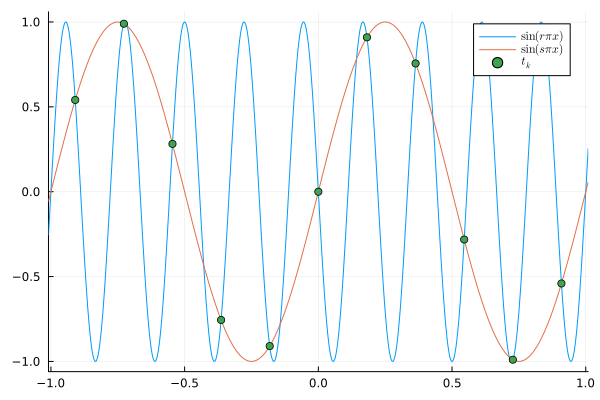

In [25]:
# (b)

s = 2;
r = -9;
N = 11;

f1(x) = sin(r * pi * x);
f2(x) = sin(s * pi * x);

plot([f1, f2], xlim = [minimum(tk) - .1, maximum(tk) + .1], labels = [L"\sin(r\pi x)" L"\sin(s\pi x)"])
scatter!(tk, f1.(tk), label = L"t_k")

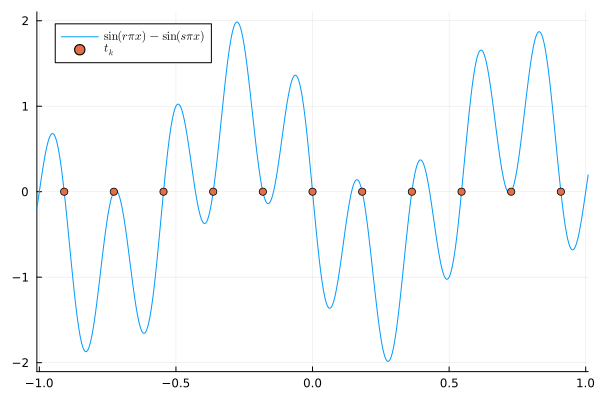

In [26]:
df = (x) -> f1(x) - f2(x)
plot(df, xlim = [minimum(tk) - .1, maximum(tk) + .1], label = L"\sin(r\pi x) - \sin(s\pi x)")
scatter!(tk, df.(tk), label = L"t_k")

## Q 9.5.5

Spectral convergence is predicated on having infinitely many continuous derivatives. At the other extreme is a function with a jump discontinuity. Trigonometric interpolation across a jump leads to a lack of convergence altogether, a fact famously known as the Gibbs phenomenon.

(a) Define `f(x) = sign(x+eps())`. This function jumps from $0$ to $1$ at $-\epsilon$. Plot the function over $[-0.05, 0.15]$.

(b) Let $n=30$ and $N=2n+1$. Using Function 9.5.3, add a plot of the trigonometric interpolant to $f$ to the graph from part (a).

(c) Repeat part (b) for $n=80$ and $n=180$.

(d) You should see that the interpolants overshoot and oscillate near the step. The widths of the overshoots decrease with 
 but the heights approach a limiting value. By zooming in to the graph, find the height of the overshoot to two decimal places.
                

In [27]:
# Function 9.5.3
"""
    triginterp(t,y)

Construct the trigonometric interpolant for the points defined by 
vectors `t` and `y`.
"""
function triginterp(t,y)
    N = length(t)

    function τ(x)
        if x==0
            return 1.0
        else
            denom = isodd(N) ? N*sin(π*x/2) : N*tan(π*x/2)
            return sin(N*π*x/2)/denom
        end
    end

    return function (x)
        sum( y[k]*τ(x-t[k]) for k in eachindex(y) )
    end
end

triginterp

_Solution_:

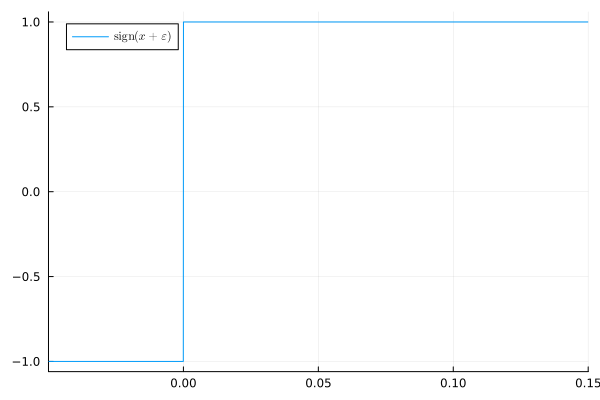

In [28]:
f(x) = sign(x+eps())

plot(f, xlim = [-0.05, 0.15], label = L"\mathrm{sign}(x+\varepsilon)")

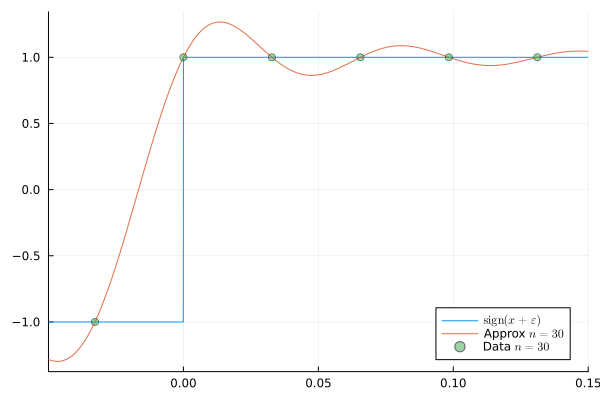

In [29]:
n = 30; 
N = 2 * n + 1;
ts = 2*(-n:n)/N
ys = f.(ts)
fun = triginterp(ts, ys)
plot!(fun, -1, 1, label = raw"Approx " * raw"$n = " * "{$(n)}" * raw"$")
scatter!(ts, ys, label = raw"Data " * raw"$n = " * "{$(n)}" * raw"$", opacity = 0.5)
current()

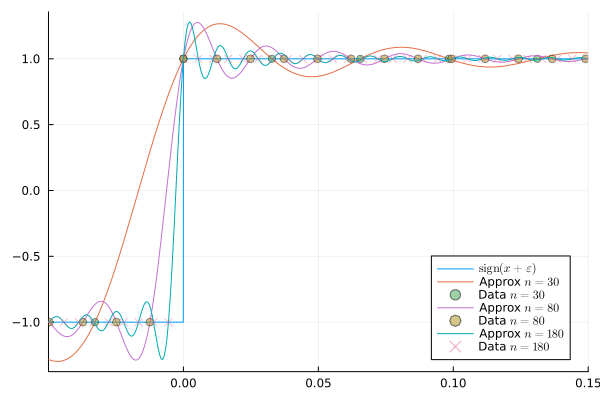

In [30]:
n = 80; 
N = 2 * n + 1;
ts = 2*(-n:n)/N
ys = f.(ts)
fun = triginterp(ts, ys)
plot!(fun, -1, 1, label = raw"Approx " * raw"$n = " * "{$(n)}" * raw"$")
scatter!(ts, ys, mark = :o, label = raw"Data " * raw"$n = " * "{$(n)}" * raw"$", opacity = 0.5)

n = 180; 
N = 2 * n + 1;
ts = 2*(-n:n)/N
ys = f.(ts)
fun = triginterp(ts, ys)
plot!(fun, -1, 1, label = raw"Approx " * raw"$n = " * "{$(n)}" * raw"$")
scatter!(ts, ys, mark = :x, label = raw"Data " * raw"$n = " * "{$(n)}" * raw"$", opacity = 0.5)


## Q 9.7.3d
For integration on a semi-infinite interval such as $[0,\infty)$, another double exponential transformation is useful: $x(t) = \exp(\sinh(t))$.

Write a function `intsemi(f,tol)` by adapting Function 9.7.3 in the book for the semi-infinite integration problem. Test it on the integral

$$\int_0^\infty \frac{e^{-x}}{\sqrt{x}} = \sqrt{\pi}.$$

Compare with the result using `quadgk` from the QuadGK package.

You'll need `intadapt` from Chapter 5, so I've copied it here.

In [31]:
function intadapt(f,a,b,tol,fa=f(a),fb=f(b),m=(a+b)/2,fm=f(m))
    # Use error estimation and recursive bisection.
    # These are the two new nodes and their f-values.
    xl = (a+m)/2;  fl = f(xl);
    xr = (m+b)/2;  fr = f(xr);
    
    # Compute the trapezoid values iteratively.
    h = (b-a)
    T = [0.,0.,0.]
    T[1] = h*(fa+fb)/2
    T[2] = T[1]/2 + (h/2)*fm
    T[3] = T[2]/2 + (h/4)*(fl+fr)
    
    S = (4T[2:3]-T[1:2]) / 3      # Simpson values
    E = (S[2]-S[1]) / 15           # error estimate
    
    if abs(E) < tol*(1+abs(S[2]))  # acceptable error?
        Q = S[2]                   # yes--done
        nodes = [a,xl,m,xr,b]      # all nodes at this level
    else
        # Error is too large--bisect and recurse.
        QL,tL = intadapt(f,a,m,tol,fa,fm,xl,fl)
        QR,tR = intadapt(f,m,b,tol,fm,fb,xr,fr)
        Q = QL + QR
        nodes = [tL;tR[2:end]]   # merge the nodes w/o duplicate
    end
    return Q,nodes
end

intadapt (generic function with 5 methods)

_Solution_:

In [32]:
function intsemi(f,tol)   
    x = t -> exp(sinh(t))
    dx_dt = t -> cosh(t)*exp(sinh(t))
    g = t -> f(x(t))*dx_dt(t)

    # Find where to truncate the integration interval.
    M = 3
    while (abs(g(-M)) > tol/100) || (abs(g(M)) > tol/100)
        M += 0.5
        if isinf(x(M)) 
            @warn "Function may not decay fast enough."
            M -= 0.5
            break
        end
    end

    I,t = intadapt(g,-M,M,tol)
	return I,x.(t)
end

intsemi (generic function with 1 method)

In [33]:
res = intsemi((x) -> exp(-x) / sqrt(x), 1e-6)

(1.772455041233968, [2.853912066288294e-20, 1.047305076987121e-17, 1.7716071483390152e-15, 1.529189428251244e-13, 7.357070993478746e-12, 4.1997533690540406e-11, 2.130199545856566e-10, 9.677925382088462e-10, 3.96790228465493e-9, 1.4783835383662816e-8  …  11.24834714080576, 13.605631155782989, 20.712703825724148, 33.48319690621568, 58.02575654373648, 108.9804279373336, 4006.68761532299, 2.180430367273218e6, 1.3592365778261388e11, 3.5039621991597236e19])

In [34]:
sqrt(pi)

1.7724538509055159

In [35]:
# verify
res[1] - sqrt(pi)

1.1903284520276003e-6